# 01 — Tìm hiểu dữ liệu và EDA

**Bài toán:** dự đoán một lượt đặt phòng có bị hủy hay không (`is_canceled`).
Thời điểm dự đoán là **lúc đặt phòng được xác nhận**, vì vậy chỉ những thông
tin đã biết tại thời điểm đó mới được dùng làm đặc trưng.

**Dữ liệu:** [Hotel booking demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)
(Kaggle, CC BY 4.0), trích từ bài báo *Antonio, Almeida & Nunes (2019), Hotel
booking demand datasets, Data in Brief 22*. Gồm các lượt đặt phòng của một City
Hotel và một Resort Hotel tại Bồ Đào Nha, ngày đến từ 07/2015 đến 08/2017.

**Nguyên tắc:** dữ liệu được chia theo thời gian **trước khi** khám phá, và mọi phân tích
dưới đây chỉ dùng **giai đoạn train** (ngày đến đến hết 12/2016, đúng phần trở thành
`train.csv` ở notebook 02). Nhờ vậy các quyết định xử lý dữ liệu và chọn kỹ thuật không
bị ảnh hưởng bởi test và production holdout (khuyến nghị *"split even before any EDA to
ensure you're blind to the test set"* trong tài liệu *Machine Learning System*). Các quy
tắc làm sạch ở notebook 02 là ngưỡng cố định, không học từ dữ liệu, nên vẫn áp dụng cho
mọi tập.

Mục cuối tổng hợp **từ phát hiện EDA đến kỹ thuật xử lý** được dùng ở notebook 02 và 03.

> Logic dùng chung (làm sạch, tạo đặc trưng, chia dữ liệu, pipeline mô hình, công cụ thí nghiệm)
> nằm trong module `src/hotel_booking/` và được kiểm thử bằng `pytest` trong thư mục `tests/`.
> Notebook chỉ gọi lại các hàm đó, nhờ vậy quá trình huấn luyện và dự đoán luôn dùng
> chung một cách xử lý.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from hotel_booking import config, data, modeling
from hotel_booking.features import LEAD_TIME_EDGES, LEAD_TIME_LABELS, BookingFeatureBuilder

RANDOM_STATE = config.RANDOM_STATE
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.4})
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

# Màu cố định theo thực thể: cùng một ý nghĩa luôn cùng một màu trong mọi notebook.
COLORS = {"primary": "#2a78d6", "not_canceled": "#2a78d6", "canceled": "#eb6834",
          "secondary": "#1baf7a", "reference": "#52514e"}

PROJECT_ROOT = config.find_project_root()
RAW_DATA_PATH = PROJECT_ROOT / "dataset" / "raw" / "hotel_bookings.csv"
PROCESSED_DIR = PROJECT_ROOT / "dataset" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
print(f"Project root: {PROJECT_ROOT}")

Project root: .

In [2]:
df_all = data.load_raw(RAW_DATA_PATH)
df_all["arrival_date"] = data.arrival_dates(df_all)
in_train = df_all["arrival_date"] <= config.TRAIN_END
display(pd.Series(np.where(in_train, "train (khám phá)", "sau train (không khám phá)"))
        .value_counts().rename("số dòng").to_frame())

# Từ đây chỉ dùng giai đoạn train; test và production holdout không được nhìn tới.
df = df_all[in_train].reset_index(drop=True)
del df_all
print(f"Shape: {df.shape}, ngày đến {df['arrival_date'].min():%Y-%m-%d} → {df['arrival_date'].max():%Y-%m-%d}")
display(df.head())

,số dòng
train (khám phá),78703
sau train (không khám phá),40687


Shape: (78703, 33), ngày đến 2015-07-01 → 2016-12-31


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0000,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0000,0,0,Check-Out,2015-07-01,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0000,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0000,0,0,Check-Out,2015-07-01,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0000,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0000,0,0,Check-Out,2015-07-02,2015-07-01
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0000,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0000,NaN,0,Transient,75.0000,0,0,Check-Out,2015-07-02,2015-07-01
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0000,NaN,0,Transient,98.0000,0,1,Check-Out,2015-07-03,2015-07-01


## 1. Từ điển dữ liệu và thời điểm biết giá trị

Cột "biết lúc đặt phòng" cho biết giá trị đã có tại thời điểm dự đoán hay chỉ được
ghi nhận sau đó. Chỉ các cột "Có" được dùng làm đầu vào mô hình; phân loại này được
khai báo một lần trong `hotel_booking.config` và kiểm chứng ở mục 6.

In [3]:
def availability(column: str) -> str:
    if column == config.TARGET:
        return "Biến đích"
    if column in config.LEAKAGE_COLUMNS:
        return "Không – chứa kết quả"
    if column in config.POST_BOOKING_COLUMNS:
        return "Không – ghi nhận sau khi đặt"
    return "Có"

raw_columns = df.columns.drop("arrival_date")
dictionary = pd.DataFrame({
    "dtype": df[raw_columns].dtypes.astype(str),
    "missing": df[raw_columns].isna().sum(),
    "missing_%": 100 * df[raw_columns].isna().mean(),
    "unique": df[raw_columns].nunique(),
    "biết lúc đặt phòng": [availability(column) for column in raw_columns],
})
display(dictionary)
assert set(raw_columns) == set(config.INPUT_COLUMNS + config.POST_BOOKING_COLUMNS
                               + config.LEAKAGE_COLUMNS + [config.TARGET])
print(f"Số dòng trùng hoàn toàn: {df[raw_columns].duplicated().sum():,}")

,dtype,missing,missing_%,unique,biết lúc đặt phòng
hotel,str,0,0.0000,2,Có
is_canceled,int64,0,0.0000,2,Biến đích
lead_time,int64,0,0.0000,439,Có
arrival_date_year,int64,0,0.0000,2,Có
arrival_date_month,str,0,0.0000,12,Có
arrival_date_week_number,int64,0,0.0000,53,Có
arrival_date_day_of_month,int64,0,0.0000,31,Có
stays_in_weekend_nights,int64,0,0.0000,17,Có
stays_in_week_nights,int64,0,0.0000,32,Có
adults,int64,0,0.0000,14,Có


Số dòng trùng hoàn toàn: 22,999


In [4]:
display(df.select_dtypes("number").describe().T)

,count,mean,std,min,25%,50%,75%,max
is_canceled,"78,703.0000",0.3619,0.4805,0.0000,0.0000,0.0000,1.0000,1.0000
lead_time,"78,703.0000",101.2985,106.2006,0.0000,16.0000,65.0000,158.0000,737.0000
arrival_date_year,"78,703.0000","2,015.7205",0.4487,"2,015.0000","2,015.0000","2,016.0000","2,016.0000","2,016.0000"
arrival_date_week_number,"78,703.0000",31.5774,13.3330,1.0000,21.0000,34.0000,42.0000,53.0000
arrival_date_day_of_month,"78,703.0000",15.8399,8.7761,1.0000,8.0000,16.0000,23.0000,31.0000
stays_in_weekend_nights,"78,703.0000",0.9040,0.9896,0.0000,0.0000,1.0000,2.0000,19.0000
stays_in_week_nights,"78,703.0000",2.4480,1.8717,0.0000,1.0000,2.0000,3.0000,50.0000
adults,"78,703.0000",1.8452,0.6176,0.0000,2.0000,2.0000,2.0000,55.0000
children,"78,699.0000",0.0923,0.3772,0.0000,0.0000,0.0000,0.0000,10.0000
babies,"78,703.0000",0.0087,0.1047,0.0000,0.0000,0.0000,0.0000,10.0000


## 2. Phân bố biến đích

,bookings,cancel_rate
hotel,,
City Hotel,"51,822.0000",0.4132
Resort Hotel,"26,881.0000",0.2629
Tổng,"78,703.0000",0.3619


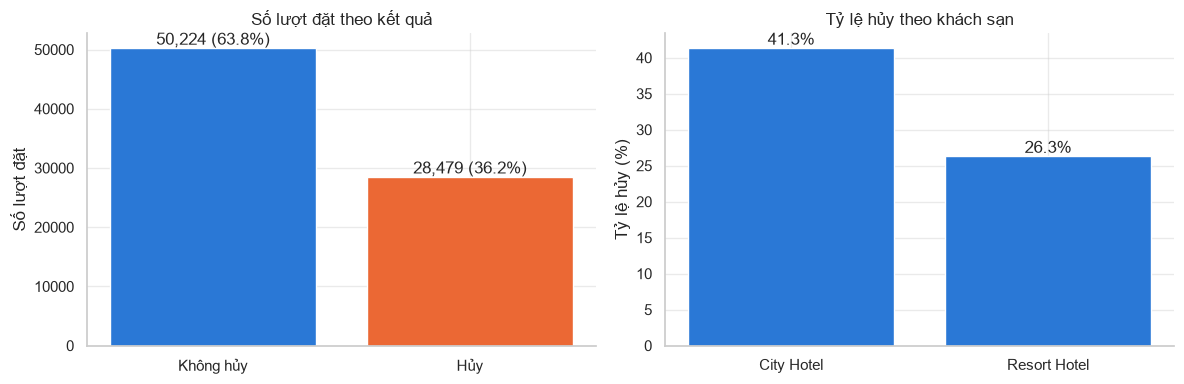

In [5]:
target_by_hotel = df.groupby("hotel")["is_canceled"].agg(bookings="size", cancel_rate="mean")
target_by_hotel.loc["Tổng"] = [len(df), df["is_canceled"].mean()]
display(target_by_hotel)

label_counts = df["is_canceled"].map({0: "Không hủy", 1: "Hủy"}).value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bars = axes[0].bar(label_counts.index, label_counts.values,
                   color=[COLORS["not_canceled"], COLORS["canceled"]])
axes[0].bar_label(bars, labels=[f"{v:,} ({100 * v / len(df):.1f}%)" for v in label_counts.values])
axes[0].set(title="Số lượt đặt theo kết quả", ylabel="Số lượt đặt")
hotel_rates = target_by_hotel.drop(index="Tổng")
bars = axes[1].bar(hotel_rates.index, 100 * hotel_rates["cancel_rate"], color=COLORS["primary"])
axes[1].bar_label(bars, fmt="%.1f%%")
axes[1].set(title="Tỷ lệ hủy theo khách sạn", ylabel="Tỷ lệ hủy (%)")
plt.tight_layout()
plt.show()

Khoảng 36% lượt đặt bị hủy: **mất cân bằng nhẹ**. Lớp hủy vẫn có hàng chục nghìn mẫu nên
không cần resampling (oversampling, SMOTE, Tomek links, undersampling); tài liệu cũng lưu
ý SMOTE và Tomek links chỉ hợp với dữ liệu ít chiều, trong khi dữ liệu ở đây có gần 200
cột sau one-hot. Notebook 03 xử lý ở mức **độ đo** và **thuật toán**: theo dõi average
precision (tập trung vào lớp hủy) bên cạnh ROC-AUC, thử `class_weight` (class-balanced
loss) như một tham số khi tinh chỉnh, và chọn ngưỡng phân loại trên dự đoán out-of-fold.
City Hotel hủy nhiều hơn Resort Hotel rõ rệt, nên kết quả trên test được báo cáo riêng
cho từng khách sạn.

## 3. Diễn biến theo thời gian

Các đường nét đứt đánh dấu đầu mỗi quý validation của cross validation ở notebook 03
(expanding window: mỗi quý của 2016 được dự đoán bởi mô hình học từ mọi dữ liệu trước đó).

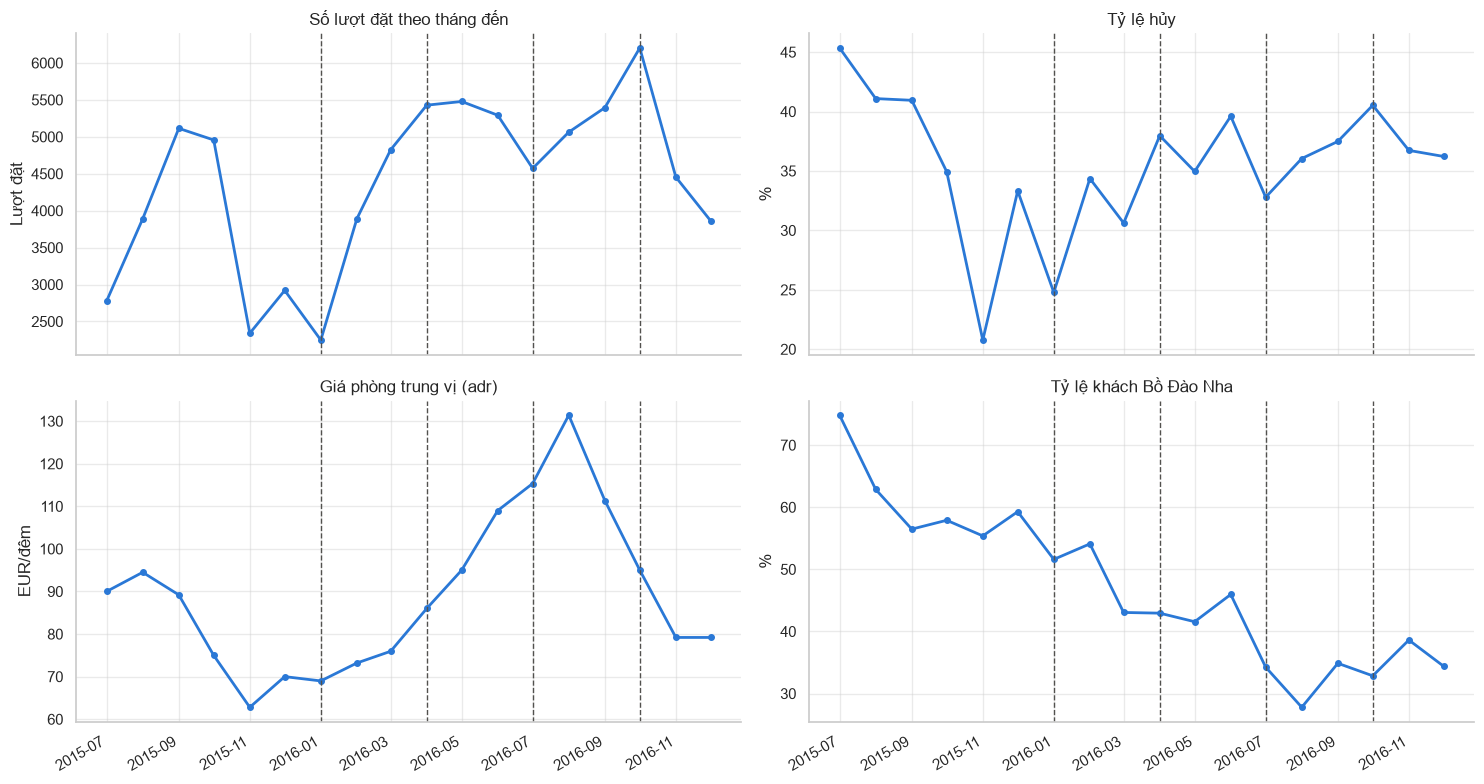

,bookings,cancel_rate,median_adr,portugal_share
arrival_date,,,,
2015Q3,11779,0.4203,90.0000,0.6291
2015Q4,10217,0.3123,70.0000,0.5772
2016Q1,10963,0.3075,72.9000,0.4873
2016Q2,16198,0.3749,95.0000,0.4346
2016Q3,15029,0.3557,118.8000,0.3230
2016Q4,14517,0.3822,85.0000,0.3503


In [6]:
FOLD_STARTS = ["2016-01-01", "2016-04-01", "2016-07-01", "2016-10-01"]

monthly = df.set_index("arrival_date").resample("MS").agg(
    bookings=("is_canceled", "size"),
    cancel_rate=("is_canceled", "mean"),
    median_adr=("adr", "median"),
    portugal_share=("country", lambda s: (s == "PRT").mean()),
)
monthly["cancel_rate"] *= 100
monthly["portugal_share"] *= 100

panels = [
    ("bookings", "Số lượt đặt theo tháng đến", "Lượt đặt"),
    ("cancel_rate", "Tỷ lệ hủy", "%"),
    ("median_adr", "Giá phòng trung vị (adr)", "EUR/đêm"),
    ("portugal_share", "Tỷ lệ khách Bồ Đào Nha", "%"),
]
fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
for ax, (column, title, ylabel) in zip(axes.flat, panels):
    ax.plot(monthly.index, monthly[column], color=COLORS["primary"], linewidth=2, marker="o", markersize=4)
    for date in FOLD_STARTS:
        ax.axvline(pd.Timestamp(date), color=COLORS["reference"], linestyle="--", linewidth=1)
    ax.set(title=title, ylabel=ylabel)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

quarterly = df.groupby(df["arrival_date"].dt.to_period("Q")).agg(
    bookings=("is_canceled", "size"), cancel_rate=("is_canceled", "mean"),
    median_adr=("adr", "median"), portugal_share=("country", lambda s: (s == "PRT").mean()))
display(quarterly)

Ngay trong giai đoạn train, dữ liệu đã thay đổi theo thời gian: lượng đặt và giá phòng có
tính mùa vụ, giá trung vị cùng quý tăng từ 2015 sang 2016 (quý 3: khoảng 90 → 119 EUR),
tỷ lệ khách Bồ Đào Nha giảm (khoảng 63% → 35%), tỷ lệ hủy theo quý dao động khoảng 31–42%.
Hệ quả:

- Chia train/test **theo thời gian** (notebook 02) và cross validation **theo quý**
  (notebook 03); chia ngẫu nhiên sẽ cho kết quả lạc quan hơn thực tế.
- Thử **trọng số ưu tiên dữ liệu gần đây** (weighted sampling) cho mọi mô hình, ý tưởng từ
  hệ thống dự đoán của nhóm tác giả bộ dữ liệu (Antonio et al. 2019).
- Giá tuyệt đối khó tổng quát hóa sang năm sau → thử **giá tương đối** (`adr` so với giá
  trung vị cùng khách sạn, loại phòng, tháng) ở notebook 03, mục 14.2.

## 4. Các yếu tố liên quan đến việc hủy phòng

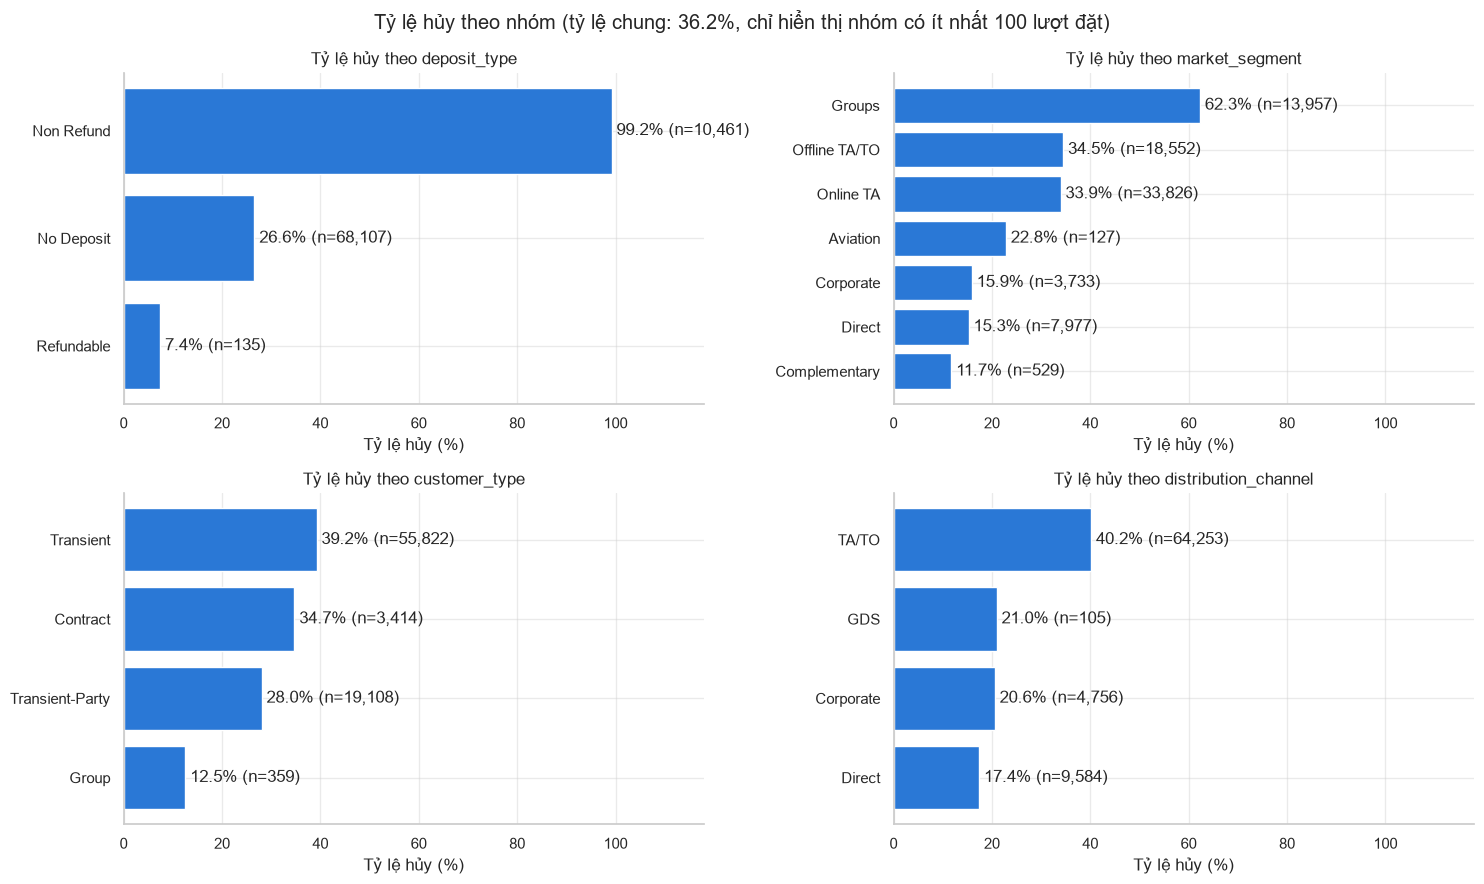

In [7]:
overall_rate = 100 * df["is_canceled"].mean()

def cancel_rate_by(column: str, min_count: int = 100) -> pd.DataFrame:
    table = df.groupby(column, observed=True)["is_canceled"].agg(bookings="size", cancel_rate="mean")
    table = table[table["bookings"] >= min_count].sort_values("cancel_rate")
    table["cancel_rate"] *= 100
    return table

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, column in zip(axes.flat, ["deposit_type", "market_segment", "customer_type", "distribution_channel"]):
    table = cancel_rate_by(column)
    bars = ax.barh(table.index.astype(str), table["cancel_rate"], color=COLORS["primary"])
    for bar, rate, count in zip(bars, table["cancel_rate"], table["bookings"]):
        ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f"{rate:.1f}% (n={count:,})", va="center")
    ax.set(title=f"Tỷ lệ hủy theo {column}", xlabel="Tỷ lệ hủy (%)", xlim=(0, 118))
fig.suptitle(f"Tỷ lệ hủy theo nhóm (tỷ lệ chung: {overall_rate:.1f}%, chỉ hiển thị nhóm có ít nhất 100 lượt đặt)")
plt.tight_layout()
plt.show()

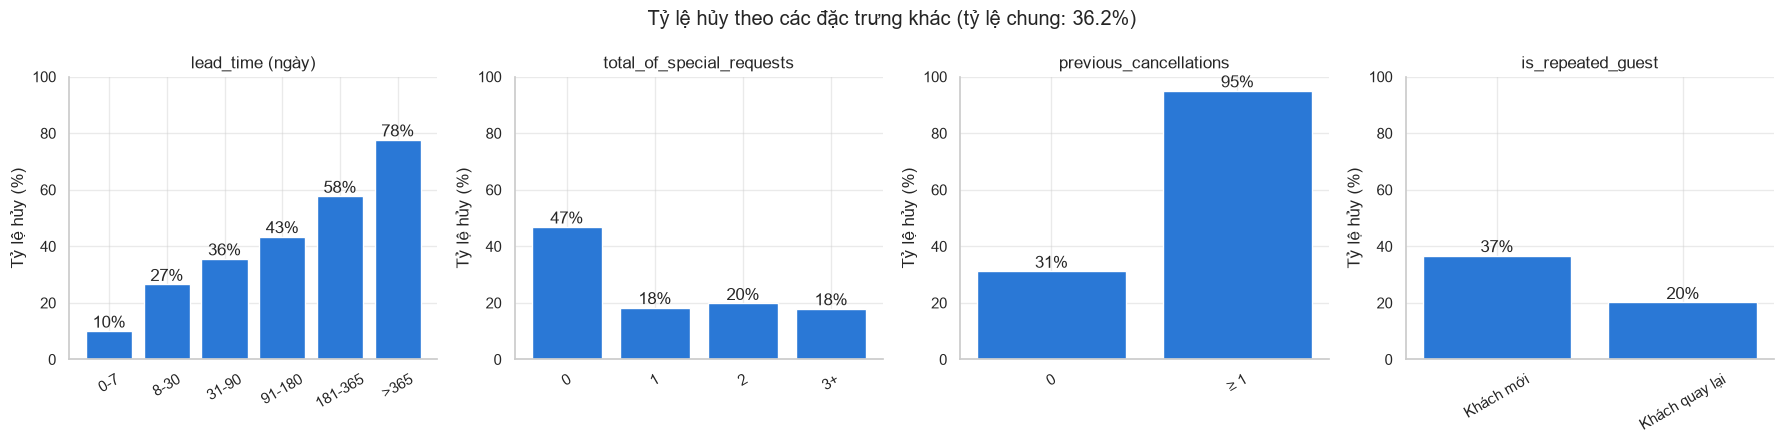

In [8]:
derived = pd.DataFrame({
    "lead_time (ngày)": pd.cut(df["lead_time"], [-np.inf] + LEAD_TIME_EDGES + [np.inf], labels=LEAD_TIME_LABELS),
    "total_of_special_requests": df["total_of_special_requests"].clip(upper=3).astype(str).replace({"3": "3+"}),
    "previous_cancellations": np.where(df["previous_cancellations"] > 0, "≥ 1", "0"),
    "is_repeated_guest": df["is_repeated_guest"].map({0: "Khách mới", 1: "Khách quay lại"}),
    "is_canceled": df["is_canceled"],
})

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, column in zip(axes, derived.columns.drop("is_canceled")):
    table = derived.groupby(column, observed=True)["is_canceled"].agg(bookings="size", cancel_rate="mean")
    bars = ax.bar(table.index.astype(str), 100 * table["cancel_rate"], color=COLORS["primary"])
    ax.bar_label(bars, fmt="%.0f%%")
    ax.set(title=column, ylabel="Tỷ lệ hủy (%)", ylim=(0, 100))
    ax.tick_params(axis="x", rotation=30)
fig.suptitle(f"Tỷ lệ hủy theo các đặc trưng khác (tỷ lệ chung: {overall_rate:.1f}%)")
plt.tight_layout()
plt.show()

grouped = df.groupby(["market_segment", "hotel", "deposit_type"])["is_canceled"]
# Chỉ hiện ô có ít nhất 100 lượt đặt để tỷ lệ đủ tin cậy.
cross_rate = (grouped.mean().where(grouped.size() >= 100)
              .unstack(["hotel", "deposit_type"]).sort_index(axis=1))
display(cross_rate.style.format("{:.0%}", na_rep="—").background_gradient(cmap="Blues", axis=None))

- Tỷ lệ hủy **tăng đều** theo khoảng `lead_time` (khoảng 10% khi đặt trước tối đa 7 ngày,
  khoảng 78% khi đặt trước hơn một năm): quan hệ đơn điệu nhưng không tuyến tính. Mô hình
  cây tự tìm ngưỡng; với Logistic Regression, notebook 03 thử **chia khoảng** theo đúng các
  mốc này (`features.LEAD_TIME_EDGES`) để mô hình tuyến tính học được từng bậc.
- Tỷ lệ hủy thay đổi theo **tổ hợp** khách sạn × phân khúc × đặt cọc (bảng chéo): trong
  cùng một phân khúc, Non Refund gần như luôn hủy còn No Deposit thì không; và cùng phân
  khúc, cùng loại đặt cọc, hai khách sạn vẫn khác nhau (ví dụ Groups không đặt cọc: khoảng
  36% ở City Hotel so với 26% ở Resort Hotel). Mô hình
  tuyến tính không tự học tương tác, nên notebook 03 thử **ghép đặc trưng** (feature
  crossing): `hotel × deposit_type`, `market_segment × deposit_type`, `hotel × market_segment`
  (`features.CROSSED_FEATURES`). Các cặp này có ít nhóm (tối đa vài chục) nên không làm
  bùng nổ số cột.

## 5. Dòng trùng lặp và đặt phòng theo đoàn

Dữ liệu không có mã đặt phòng. Các dòng giống hệt nhau ở mọi thông tin lúc đặt
(cùng ngày đặt, ngày đến, số đêm, giá, đại lý...) nhiều khả năng là **nhiều phòng
trong cùng một lượt đặt theo đoàn**. Số dòng như vậy (`rooms_in_booking`) là thông
tin biết ngay lúc đặt, và được tính **không dùng biến đích** nên không gây rò rỉ.

Số dòng trùng hoàn toàn (mọi cột): 22,999
Tỷ lệ dòng thuộc lượt đặt nhiều phòng: 41.5%


,bookings,cancel_rate,non_refund_share,groups_or_offline_share,share_of_rows
rooms_in_booking,,,,,
1,46014,0.2437,0.0025,0.1902,0.5847
2–4,11033,0.3011,0.0254,0.3372,0.1402
5–9,3210,0.3710,0.1006,0.6838,0.0408
10+,18446,0.6913,0.5282,0.9673,0.2344


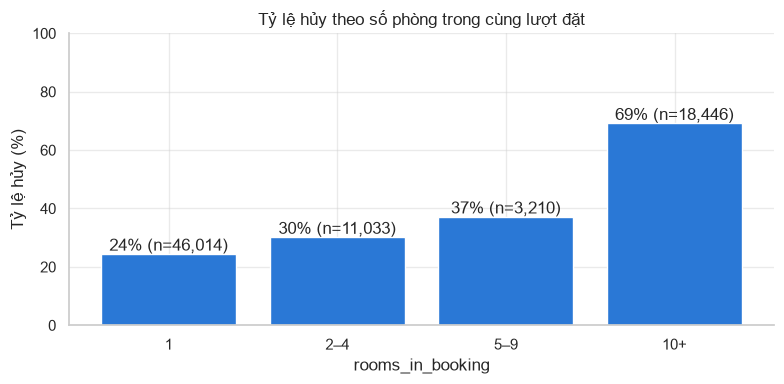

Tỷ lệ hủy theo dòng (mỗi phòng một mẫu):          0.362
Tỷ lệ hủy theo lượt đặt (trọng số 1 / số phòng):  0.256
Tỷ lệ hủy sau khi bỏ dòng trùng:                  0.250


In [9]:
df["rooms_in_booking"] = data.add_group_size(df)
print(f"Số dòng trùng hoàn toàn (mọi cột): {df.duplicated(subset=raw_columns).sum():,}")
print(f"Tỷ lệ dòng thuộc lượt đặt nhiều phòng: {(df['rooms_in_booking'] > 1).mean():.1%}")

group_bucket = pd.cut(df["rooms_in_booking"], [0, 1, 4, 9, np.inf], labels=["1", "2–4", "5–9", "10+"])
group_summary = df.groupby(group_bucket, observed=True).agg(
    bookings=("is_canceled", "size"),
    cancel_rate=("is_canceled", "mean"),
    non_refund_share=("deposit_type", lambda s: (s == "Non Refund").mean()),
    groups_or_offline_share=("market_segment", lambda s: s.isin(["Groups", "Offline TA/TO"]).mean()),
)
group_summary["share_of_rows"] = group_summary["bookings"] / len(df)
display(group_summary)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(group_summary.index.astype(str), 100 * group_summary["cancel_rate"], color=COLORS["primary"])
ax.bar_label(bars, labels=[f"{r:.0%} (n={n:,})" for r, n in zip(group_summary["cancel_rate"], group_summary["bookings"])])
ax.set(title="Tỷ lệ hủy theo số phòng trong cùng lượt đặt", xlabel="rooms_in_booking", ylabel="Tỷ lệ hủy (%)", ylim=(0, 100))
plt.tight_layout()
plt.show()

booking_weight = 1 / df["rooms_in_booking"]
deduplicated = df.drop_duplicates(subset=raw_columns)
print(f"Tỷ lệ hủy theo dòng (mỗi phòng một mẫu):          {df['is_canceled'].mean():.3f}")
print(f"Tỷ lệ hủy theo lượt đặt (trọng số 1 / số phòng):  {np.average(df['is_canceled'], weights=booking_weight):.3f}")
print(f"Tỷ lệ hủy sau khi bỏ dòng trùng:                  {deduplicated['is_canceled'].mean():.3f}")

Lượt đặt càng nhiều phòng càng hay bị hủy và gần như toàn bộ đi qua nhóm Groups /
Offline TA/TO với đặt cọc Non Refund. Khoảng 23% dòng thuộc lượt đặt từ 10 phòng trở lên;
tính theo lượt đặt, tỷ lệ hủy chỉ khoảng 26% thay vì 36%.

**Quyết định:**

- Giữ các dòng trùng (mỗi dòng là một phòng bị giữ chỗ) và dùng `rooms_in_booking` làm
  đặc trưng. Các dòng trùng có cùng ngày đến nên khi chia theo thời gian chúng luôn rơi vào
  cùng một tập và cùng một fold CV: không có rò rỉ theo nhóm (group leakage).
- Vì các khối phòng đoàn chiếm nhiều dòng và dễ đoán, độ đo tính theo dòng có thể đẹp hơn
  chất lượng trên từng lượt đặt. Notebook 03 báo cáo **thêm độ đo theo lượt đặt** (trọng số
  1 / số phòng) trong mọi bảng, và thử **huấn luyện theo lượt đặt** ở mục 14.3.

## 6. Kiểm tra rò rỉ dữ liệu (data leakage)

Một cột bị coi là rò rỉ nếu giá trị của nó chỉ được ghi nhận **sau** thời điểm
dự đoán, hoặc được ghi nhận khác nhau tùy theo khách có hủy hay không.

In [10]:
display(pd.crosstab(df["reservation_status"], df["is_canceled"], margins=True))

canceled = df[df["is_canceled"] == 1]
days_before_arrival = (canceled["arrival_date"] - pd.to_datetime(canceled["reservation_status_date"])).dt.days
print(f"Với đơn bị hủy, reservation_status_date là ngày hủy: trung vị {days_before_arrival.median():.0f} ngày trước ngày đến.")

def rate_pair(mask: pd.Series) -> tuple[float, float]:
    return 100 * df.loc[mask, "is_canceled"].mean(), 100 * df.loc[~mask, "is_canceled"].mean()

checks = {
    "required_car_parking_spaces > 0": df["required_car_parking_spaces"] > 0,
    "assigned_room_type ≠ reserved_room_type": df["assigned_room_type"] != df["reserved_room_type"],
    "booking_changes > 0": df["booking_changes"] > 0,
    "country = PRT": df["country"] == "PRT",
}
leakage_evidence = pd.DataFrame(
    [(name, int(mask.sum()), *rate_pair(mask)) for name, mask in checks.items()],
    columns=["điều kiện", "số dòng thỏa", "tỷ lệ hủy khi đúng (%)", "tỷ lệ hủy khi sai (%)"],
)
display(leakage_evidence)

is_canceled,0,1,All
reservation_status,,,
Canceled,0,27620,27620
Check-Out,50224,0,50224
No-Show,0,859,859
All,50224,28479,78703


Với đơn bị hủy, reservation_status_date là ngày hủy: trung vị 47 ngày trước ngày đến.


,điều kiện,số dòng thỏa,tỷ lệ hủy khi đúng (%),tỷ lệ hủy khi sai (%)
0,required_car_parking_spaces > 0,5210,0.0000,38.7506
1,assigned_room_type ≠ reserved_room_type,11466,4.7009,41.5545
2,booking_changes > 0,11645,14.6758,39.9207
3,country = PRT,35628,56.0991,19.7145


- `reservation_status` trùng khớp hoàn toàn với `is_canceled`, còn
  `reservation_status_date` là ngày hủy hoặc ngày trả phòng. Cả hai **phải loại bỏ**.
  Đây cũng là nguyên nhân các notebook phổ biến trên Kaggle đạt 95–100% accuracy.
- `required_car_parking_spaces`, `assigned_room_type` và `booking_changes` được ghi
  nhận khi khách đến hoặc trong suốt quá trình đặt phòng: không có đơn nào yêu cầu chỗ
  đỗ xe mà bị hủy, và phòng được xếp khác phòng đã đặt gần như chỉ xảy ra khi khách đến.
- `country`: bài báo gốc cho biết quốc tịch thường chỉ được xác nhận lúc check-in, nên
  đơn bị hủy hay mang giá trị mặc định là PRT.

Cả sáu cột này **không** được dùng làm đầu vào mô hình. Notebook 03 vẫn kiểm tra thêm bằng
**ablation** (bỏ từng nhóm đặc trưng, mục 14.1): một nhóm làm điểm thay đổi bất thường là
dấu hiệu cần xem lại.

## 7. Bất thường của đặt cọc Non Refund

Gần như toàn bộ đơn đặt cọc không hoàn lại (Non Refund) bị hủy, ngược với trực giác
(đã trả tiền thì ít hủy hơn). So sánh hồ sơ của nhóm này với phần còn lại:

In [11]:
profile = df.assign(deposit=np.where(df["deposit_type"] == "Non Refund", "Non Refund", "Khác")).groupby("deposit").agg(
    bookings=("is_canceled", "size"),
    cancel_rate=("is_canceled", "mean"),
    median_lead_time=("lead_time", "median"),
    median_rooms_in_booking=("rooms_in_booking", "median"),
    groups_or_offline_share=("market_segment", lambda s: s.isin(["Groups", "Offline TA/TO"]).mean()),
    portugal_share=("country", lambda s: (s == "PRT").mean()),
    special_requests_mean=("total_of_special_requests", "mean"),
    repeated_guest_share=("is_repeated_guest", "mean"),
)
display(profile.T)

deposit,Khác,Non Refund
bookings,"68,242.0000","10,461.0000"
cancel_rate,0.2653,0.9919
median_lead_time,50.0000,238.0000
median_rooms_in_booking,1.0000,25.0000
groups_or_offline_share,0.3262,0.9799
portugal_share,0.3746,0.9619
special_requests_mean,0.5959,0.0022
repeated_guest_share,0.0345,0.0060


Đơn Non Refund có thời gian đặt trước rất dài, thường thuộc lượt đặt nhiều phòng qua
đại lý/đoàn, hầu như không có yêu cầu đặc biệt, và gần như toàn bộ ghi quốc tịch PRT (khớp
với nhận xét ở mục 6 rằng `country` của đơn bị hủy thường mang giá trị mặc định). Một giả
thuyết hợp lý là đây là các khối phòng giữ chỗ của đại lý, được trả lại khi không bán hết,
chứ không phải khách lẻ đã thanh toán.

`deposit_type` biết được lúc đặt phòng nên vẫn là đầu vào hợp lệ, nhưng quy luật này có thể
là **đặc thù của cách dữ liệu được tạo và ghi nhận** ở hai khách sạn (một nguồn rò rỉ được
nêu trong tài liệu: *leakage from data generation & collection process*). Notebook 03 đo
mức phụ thuộc của mô hình vào cột này bằng ablation (mục 14.1).

## 8. Giá trị bất thường

,số dòng
Tổng số khách = 0,113
adr < 0,0
adr > 1000,1
adr = 0 (phòng miễn phí),1504
Tổng số đêm = 0 (day use),571
children hoặc babies > 5,3
meal = Undefined,756
market_segment = Undefined,2
distribution_channel = Undefined,5


5 giá trị adr lớn nhất: [382.0, 384.0, 451.5, 508.0, 5400.0]


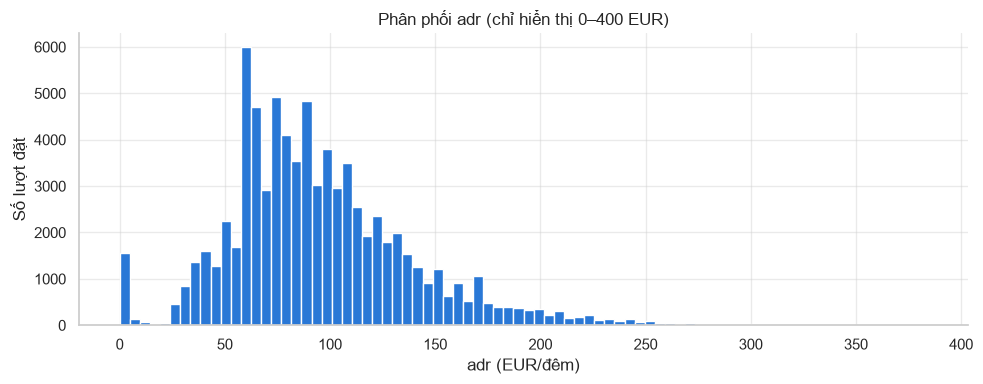

In [12]:
total_guests = df["adults"] + df["children"].fillna(0) + df["babies"]
total_nights = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
anomalies = pd.Series({
    "Tổng số khách = 0": (total_guests == 0).sum(),
    "adr < 0": (df["adr"] < 0).sum(),
    "adr > 1000": (df["adr"] > 1000).sum(),
    "adr = 0 (phòng miễn phí)": (df["adr"] == 0).sum(),
    "Tổng số đêm = 0 (day use)": (total_nights == 0).sum(),
    "children hoặc babies > 5": ((df["children"] > 5) | (df["babies"] > 5)).sum(),
    "meal = Undefined": (df["meal"] == "Undefined").sum(),
    "market_segment = Undefined": (df["market_segment"] == "Undefined").sum(),
    "distribution_channel = Undefined": (df["distribution_channel"] == "Undefined").sum(),
}, name="số dòng").to_frame()
display(anomalies)
print("5 giá trị adr lớn nhất:", sorted(df["adr"].nlargest(5).tolist()))

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df.loc[df["adr"].between(0, 400), "adr"], bins=80, color=COLORS["primary"])
ax.set(title="Phân phối adr (chỉ hiển thị 0–400 EUR)", xlabel="adr (EUR/đêm)", ylabel="Số lượt đặt")
plt.tight_layout()
plt.show()

`adr = 0` và đơn không qua đêm vẫn có thể là đơn hợp lệ (phòng miễn phí, thuê trong
ngày) nên được giữ lại. `meal = Undefined` tương đương `SC` (không kèm bữa ăn) theo mô
tả của bài báo gốc. Các dòng có tổng số khách bằng 0, `adr` âm hoặc lớn bất thường sẽ bị
loại ở notebook 02 bằng **ngưỡng cố định** (không phải thống kê học từ dữ liệu), nên áp
dụng cho mọi tập mà không gây rò rỉ.

## 9. Tương quan giữa các biến số

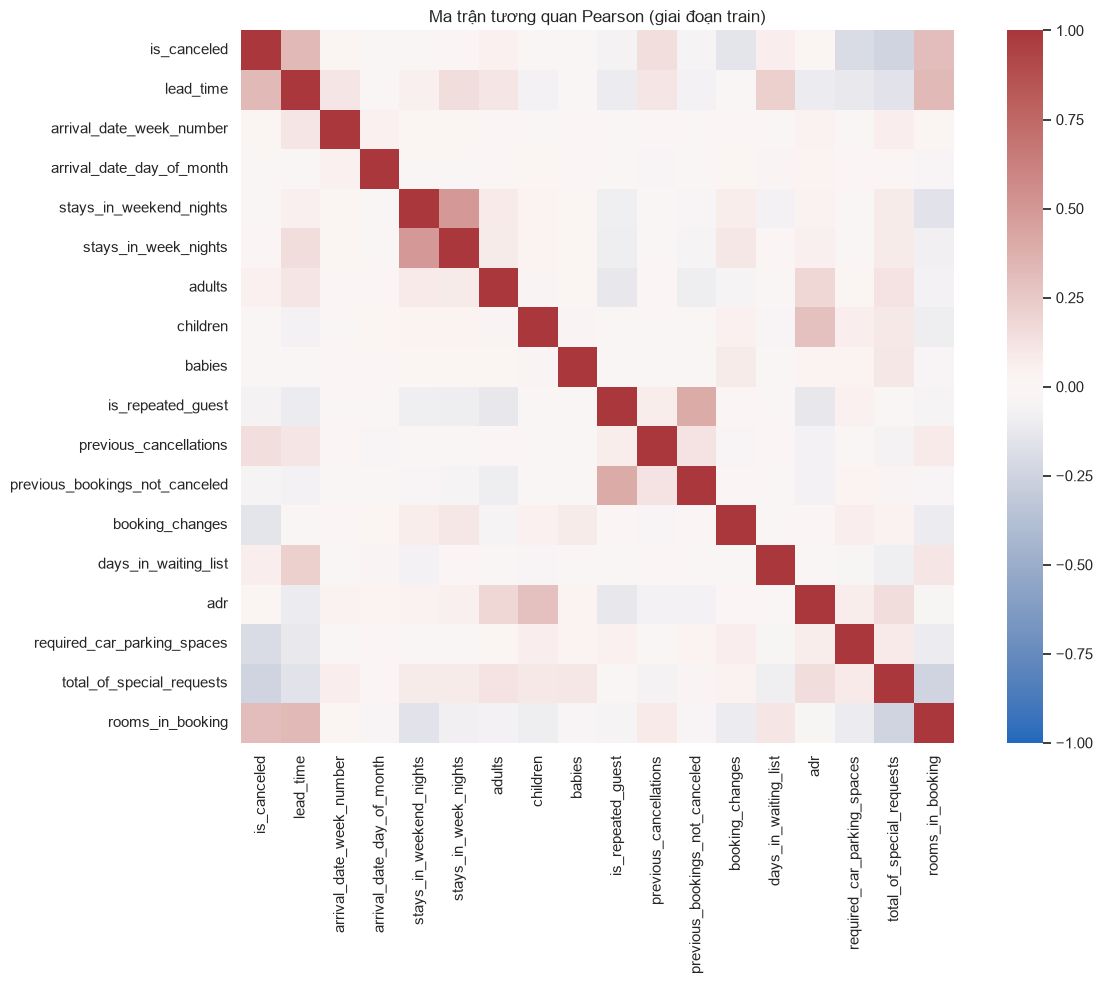

,corr_with_target
lead_time,0.3315
rooms_in_booking,0.3089
total_of_special_requests,-0.2468
required_car_parking_spaces,-0.2001
booking_changes,-0.1451
previous_cancellations,0.1426
days_in_waiting_list,0.0693
is_repeated_guest,-0.0595
previous_bookings_not_canceled,-0.0518
adults,0.0505


In [13]:
numeric_columns = df.select_dtypes("number").columns.drop(["arrival_date_year", "agent", "company"])
correlation = df[numeric_columns].corr()
plt.figure(figsize=(13, 10))
sns.heatmap(correlation, cmap="vlag", center=0, vmin=-1, vmax=1, square=True)
plt.title("Ma trận tương quan Pearson (giai đoạn train)")
plt.tight_layout()
plt.show()
display(correlation["is_canceled"].drop("is_canceled").sort_values(key=np.abs, ascending=False).to_frame("corr_with_target"))

Tương quan Pearson chỉ đo quan hệ **tuyến tính** từng cặp (tài liệu: *measure correlation
between features and labels*). `lead_time`, `rooms_in_booking` và
`total_of_special_requests` tương quan mạnh nhất với việc hủy; `required_car_parking_spaces`
và `booking_changes` cũng mạnh nhưng là cột sau lúc đặt (mục 6) nên không dùng. Nhiều biến
có tương quan tuyến tính yếu nhưng vẫn có thể quan trọng theo cách phi tuyến hoặc qua tương
tác (mục 4), vì vậy notebook 03 so sánh cả mô hình tuyến tính lẫn mô hình cây.

## 10. Phân phối biến số: độ lệch và giá trị 0

Mô hình tuyến tính và mô hình dựa trên khoảng cách (Logistic Regression, KNN, SVM) nhạy
với thang đo: một cột có đuôi dài sẽ chi phối hệ số hoặc khoảng cách. Theo bảng scaling của
tài liệu, z-score hợp với biến gần phân phối chuẩn, còn **log** hợp với biến lệch phải
(phân phối dạng mũ). Bảng dưới tính trên các đặc trưng số do pipeline tạo ra
(`BookingFeatureBuilder`), sau khi bỏ các dòng bất thường mà notebook 02 sẽ loại (mục 8),
tức đúng dữ liệu mô hình được học.

,skew,tỷ lệ = 0,p99,max,số giá trị,log1p trong pipeline
adults,23.5132,0.0020,3.0000,55.0000,14,True
previous_bookings_not_canceled,22.4294,0.9722,3.0000,58.0000,59,True
previous_cancellations,20.2919,0.9211,1.0000,26.0000,15,True
total_guests,14.1592,0.0000,4.0000,55.0000,13,True
babies,11.1854,0.9916,0.0000,2.0000,3,True
days_in_waiting_list,9.8761,0.9556,98.0000,391.0000,104,True
is_repeated_guest,5.4769,0.9697,1.0000,1.0000,2,False
children,4.2899,0.9359,2.0000,3.0000,4,True
rooms_in_booking,4.2092,0.0000,96.0000,180.0000,74,True
has_company,3.8270,0.9431,1.0000,1.0000,2,False


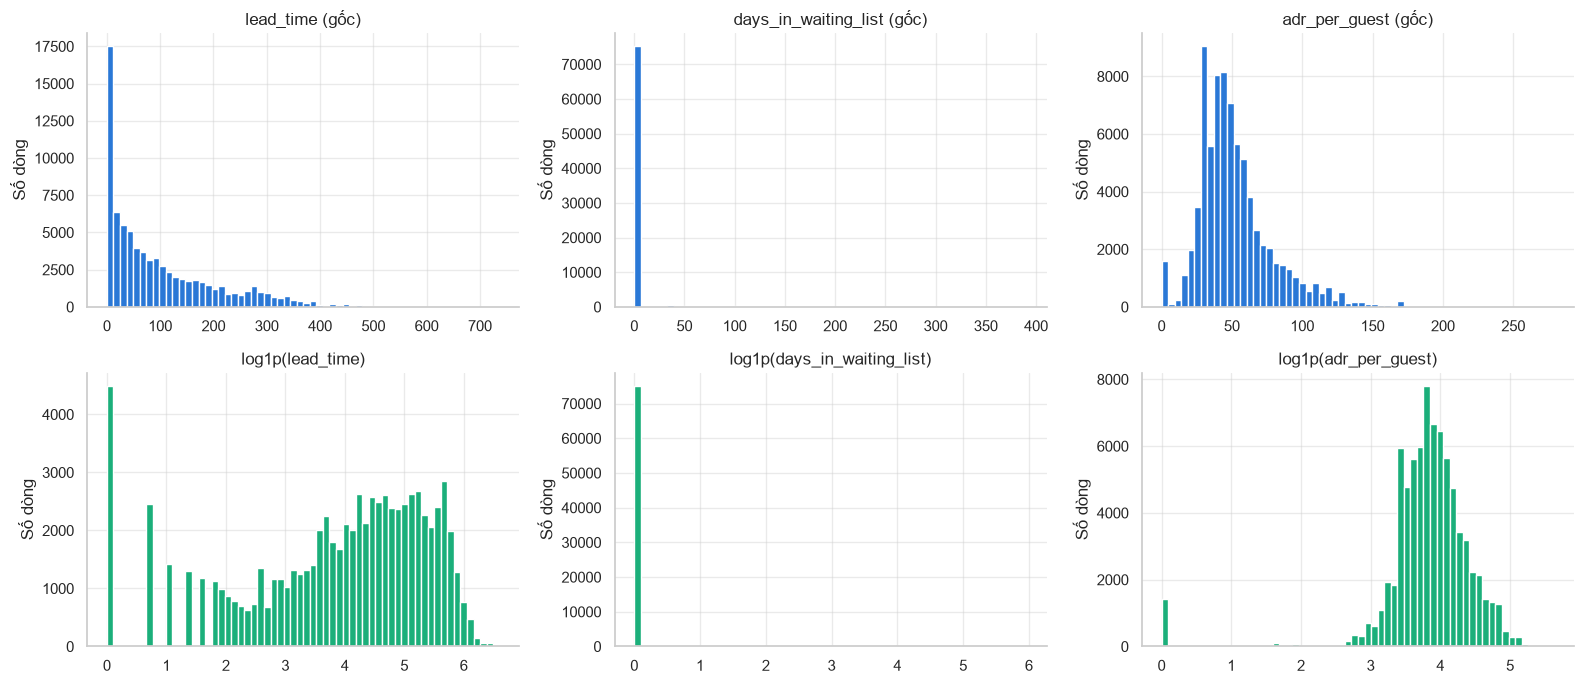

In [14]:
cleaned, _ = data.clean_bookings(df.drop(columns=["arrival_date", "rooms_in_booking"]))
engineered = BookingFeatureBuilder().fit(cleaned).transform(cleaned)
numeric_features = engineered.select_dtypes("number")
distribution = pd.DataFrame({
    "skew": numeric_features.skew(),
    "tỷ lệ = 0": (numeric_features == 0).mean(),
    "p99": numeric_features.quantile(0.99),
    "max": numeric_features.max(),
    "số giá trị": numeric_features.nunique(),
})
distribution["log1p trong pipeline"] = distribution.index.isin(modeling.LOG_FEATURES)
display(distribution.sort_values("skew", ascending=False))

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for column, (top, bottom) in zip(["lead_time", "days_in_waiting_list", "adr_per_guest"], axes.T):
    values = numeric_features[column].dropna()
    top.hist(values, bins=60, color=COLORS["primary"])
    top.set(title=f"{column} (gốc)", ylabel="Số dòng")
    bottom.hist(np.log1p(values.clip(lower=0)), bins=60, color=COLORS["secondary"])
    bottom.set(title=f"log1p({column})", ylabel="Số dòng")
plt.tight_layout()
plt.show()

**Quyết định:** các biến đếm / số tiền không âm có skew từ khoảng 1 trở lên (cột `log1p
trong pipeline`, khai báo ở `modeling.LOG_FEATURES`; `adr` có skew xấp xỉ 1 và được giữ vì là
biến tiền có đuôi phải dài) được lấy log1p rồi mới chuẩn hóa z-score
khi huấn luyện LR, KNN, SVM (tùy chọn `log_skewed`, notebook 03 bước X.2). Giá trị ngoại
lai như `adults = 55` không bị xóa: log1p làm giảm ảnh hưởng của chúng mà không mất dòng.
Các cột nhị phân (`is_family`, `has_agent`...) và tỷ lệ (`previous_cancel_ratio`) không lấy
log. Mô hình cây chỉ dùng thứ tự giá trị nên không cần biến đổi; thống kê chuẩn hóa (trung
bình, độ lệch chuẩn) được học bên trong pipeline từ phần train của từng fold.

## 11. Biến phân loại nhiều nhóm và giá trị thiếu

In [15]:
categorical = ["hotel", "meal", "market_segment", "distribution_channel", "reserved_room_type",
               "deposit_type", "customer_type", "agent", "company"]
min_frequency = modeling.MIN_CATEGORY_FREQUENCY

def frequent_share(column: str) -> tuple[int, float]:
    counts = df[column].value_counts()
    frequent = counts[counts >= min_frequency]
    return len(frequent), frequent.sum() / df[column].notna().sum()

cardinality = pd.DataFrame({
    "số nhóm": [df[column].nunique() for column in categorical],
    f"nhóm có ≥ {min_frequency} dòng": [frequent_share(column)[0] for column in categorical],
    "tỷ lệ dòng thuộc các nhóm đó": [frequent_share(column)[1] for column in categorical],
    "tỷ lệ thiếu": [df[column].isna().mean() for column in categorical],
}, index=categorical)
display(cardinality)

missing_effect = pd.DataFrame({
    column: df.groupby(df[column].isna())["is_canceled"].agg(["mean", "size"]).rename(index={False: "có giá trị", True: "thiếu"}).stack()
    for column in ["agent", "company"]
}).T
display(missing_effect)

,số nhóm,nhóm có ≥ 30 dòng,tỷ lệ dòng thuộc các nhóm đó,tỷ lệ thiếu
hotel,2,2,1.0000,0.0000
meal,5,5,1.0000,0.0000
market_segment,8,7,1.0000,0.0000
distribution_channel,5,4,0.9999,0.0000
reserved_room_type,10,8,0.9998,0.0000
deposit_type,3,3,1.0000,0.0000
customer_type,4,4,1.0000,0.0000
agent,284,121,0.9794,0.1356
company,298,25,0.6751,0.9430


có giá trị              thiếu            
              mean        size   mean        size
agent       0.3863 68,027.0000 0.2063 10,676.0000
company     0.1607  4,487.0000 0.3740 74,216.0000

**Mã hóa biến phân loại nhiều nhóm:** `agent` có gần 300 nhóm, nhưng chỉ khoảng 120 nhóm
có từ 30 dòng trở lên và chúng chiếm khoảng 98% số dòng có agent. One-hot với
`min_frequency = 30` gộp các nhóm hiếm và nhóm mới xuất hiện vào một nhóm "infrequent",
đúng cách tài liệu đề xuất (*group bottom brands and newcomers into UNKNOWN*). Hashing trick
không cần vì số nhóm nhỏ. **Target encoding** (`sklearn.preprocessing.TargetEncoder`, học
trên phần train với cross fitting bên trong để không rò nhãn) được thử ở bước X.2 của các
mô hình: mỗi cột phân loại chỉ còn một số, giúp KNN và SVM bớt số chiều, và giúp cây chia
`agent` bằng một ngưỡng.

**Giá trị thiếu không ngẫu nhiên:** thiếu `agent` / `company` nghĩa là không qua đại lý /
công ty, và tỷ lệ hủy của hai nhóm khác hẳn nhau (*missing not at random: missing
information is information itself*). Vì vậy không xóa dòng và không điền bằng một giá trị có
thật; pipeline giữ nhóm `"none"` cho `agent` và thêm cờ `has_agent`, `has_company`.
`company` thiếu khoảng 94% nên chỉ dùng cờ `has_company`. `children` chỉ thiếu vài dòng,
được điền 0.

## 12. Độ phủ tháng trong các fold cross validation

Cross validation ở notebook 03 dùng 4 fold expanding window theo quý 2016. Bảng dưới cho
biết phần train của mỗi fold đã có những tháng đến nào.

In [16]:
folds, fold_table = data.quarterly_folds(df["arrival_date"])
months = df["arrival_date"].dt.month
fold_table["tháng có trong phần train"] = [", ".join(map(str, sorted(set(months.iloc[train])))) for train, _ in folds]
fold_table["tháng validation chưa có trong train"] = [
    ", ".join(map(str, sorted(set(months.iloc[valid]) - set(months.iloc[train])))) or "—" for train, valid in folds]
display(fold_table)

,fold,train_rows,valid_from,valid_to,valid_rows,tháng có trong phần train,tháng validation chưa có trong train
0,2016Q1,21996,2016-01-01,2016-03-31,10963,"7, 8, 9, 10, 11, 12","1, 2, 3"
1,2016Q2,32959,2016-04-01,2016-06-30,16198,"1, 2, 3, 7, 8, 9, 10, 11, 12","4, 5, 6"
2,2016Q3,49157,2016-07-01,2016-09-30,15029,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12",—
3,2016Q4,64186,2016-10-01,2016-12-31,14517,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12",—


Fold 2016Q1 chỉ học từ 07–12/2015, còn fold 2016Q2 chưa có tháng 4–6: hai fold đầu đánh giá
trên những tháng mà phần train **chưa từng thấy**, nên các đặc trưng mùa vụ (`arrival_month`,
`arrival_date_week_number`) không phát huy được ở hai fold này. Đây không phải rò rỉ, nhưng
giải thích vì sao điểm giữa các fold chênh nhau. Notebook 03 hiển thị điểm **từng fold** ở
mọi giai đoạn để đọc kết quả cho đúng. Test set (01–04/2017) thì có các tháng này trong train.

## Kết luận: từ EDA đến kỹ thuật xử lý

Toàn bộ phân tích ở trên chỉ dùng giai đoạn train (07/2015 – 12/2016).

| Phát hiện | Kỹ thuật | Dùng ở |
|---|---|---|
| `reservation_status*` chứa đáp án; 4 cột chỉ có sau lúc đặt (mục 6) | Loại khỏi đầu vào; chỉ 25 cột biết lúc đặt + `rooms_in_booking` | `config`, notebook 02 |
| Dữ liệu thay đổi theo thời gian (mục 3) | Chia theo thời gian; CV expanding window theo quý; trọng số ưu tiên dữ liệu gần đây | 02 mục 3; 03 bước X.3 |
| Dòng trùng = phòng trong lượt đặt theo đoàn, chiếm nhiều dòng và hay hủy (mục 5) | Giữ dòng trùng, đặc trưng `rooms_in_booking`; độ đo theo lượt đặt; thử trọng số 1 / số phòng | 02 mục 2; 03 mọi bảng, mục 14.3 |
| 36% đơn bị hủy: mất cân bằng nhẹ (mục 2) | Không resampling; theo dõi average precision; `class_weight` khi tinh chỉnh; ngưỡng chọn trên OOF | 03 bước X.4, mục 15 |
| Cột số lệch phải, nhiều giá trị 0 (mục 10) | log1p trước chuẩn hóa cho LR, KNN, SVM | 03 bước X.2 |
| Tỷ lệ hủy tăng đều theo `lead_time` (mục 4) | Chia khoảng `lead_time` cho LR | 03 mục 2.2 |
| Tỷ lệ hủy phụ thuộc tổ hợp khách sạn × phân khúc × đặt cọc (mục 4) | Ghép đặc trưng cho LR | 03 mục 2.2 |
| `agent` nhiều nhóm, phần lớn dòng nằm ở ~120 nhóm (mục 11) | One-hot + gộp nhóm hiếm; thử target encoding | 03 bước X.2 |
| Thiếu `agent` / `company` mang thông tin (mục 11) | Nhóm `"none"` + cờ `has_agent`, `has_company` | `features` |
| Giá phòng tăng qua các năm (mục 3) | Thử giá tương đối `adr_relative` | 03 mục 14.2 |
| Non Refund gần như luôn hủy (mục 7) | Ablation đo mức phụ thuộc vào `deposit_type` | 03 mục 14.1 |
| Giá trị bất thường (mục 8) | Loại theo ngưỡng cố định | 02 mục 2 |
| Hai fold CV đầu có tháng chưa thấy (mục 12) | Đọc điểm theo từng fold | 03 mọi giai đoạn |